# Projeto de Inteligência Artificial — Distribuição de Produtos Locais

**Unidade Curricular:** Inteligência Artificial  
**Ano Letivo:** 2026/2027  
**Grupo:** G05  

**Elementos do grupo:**
- David Faria - 31517
- Francisco Campinho - 31079
- Rafael Costa - 31524
- Miguel Marques - 33221

## 1. Introdução

O problema consiste em planear as rotas de veículos que **recolhem** produtos alimentares em produtores locais, os levam ao **armazém** (centro de recolha) e os **entregam** aos clientes, sempre pela ordem produtor → armazém → cliente.

As rotas têm de respeitar:
- as **janelas de tempo** de recolha e de entrega (o serviço começa dentro da janela);
- a **capacidade** dos veículos;
- o máximo de **24 horas** de permanência no armazém;
- o **horizonte** de 2 dias (os veículos começam e acabam no armazém);
- os tempos de serviço (10 min em produtores e clientes, 15 min no armazém);
- as encomendas são carregadas e entregues **inteiras**.

**Objetivo:** encontrar rotas válidas que **minimizem os km percorridos**.

Foram usados dois datasets, `tiny` e `small`, e quatro técnicas de IA: **Greedy Best-First Search** e **A\*** (pesquisa informada), **Hill-Climbing** (pesquisa local) e **CSP** (satisfação de restrições).

| Notebook | Conteúdo |
|---|---|
| `01_Project01_G05.ipynb` | este notebook: resumo, modelação, resultados e comparação |
| `02_eda_tiny.ipynb`, `02_eda_small.ipynb` | análise exploratória dos dados (um notebook por dataset) |
| `informed_search.ipynb` | Greedy e A\* |
| `local_search.ipynb` | Hill-Climbing |
| `csp.ipynb` | CSP |

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt

# Pasta principal do projeto (funciona a partir da raiz ou da pasta notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.model import Problem, check_solution, print_solution
from src.informed import greedy_search, heuristica1, heuristica2, a_star_search, astar_h1, astar_h2
from src.local_search import hill_climbing
from src.csp import resolver_csp

problemas = {nome: Problem.from_csv(RAIZ / nome) for nome in ["data_tiny", "data_small"]}

## 2. Resumo da análise exploratória (EDA)

A análise completa está nos notebooks de EDA (`02_eda_tiny.ipynb` e `02_eda_small.ipynb`). Aqui resumem-se os números mais importantes dos dois datasets.

In [2]:
linhas = []
for nome, p in problemas.items():
    pesos = {o: sum(p.request[i].weight_kg for i in ids) for o, ids in p.orders.items()}
    horas = lambda a, b: (b - a).total_seconds() / 3600
    linhas.append({
        "Dataset": nome,
        "Produtores": len({r.pickup_location for r in p.requests}),
        "Locais de entrega": len({r.delivery_location for r in p.requests}),
        "Encomendas": len(p.orders),
        "Itens": len(p.requests),
        "Veículos (kg)": " / ".join(f"{v.capacity_kg:.0f}" for v in p.vehicles),
        "Peso total (kg)": round(sum(pesos.values()), 1),
        "Encomenda mais pesada (kg)": round(max(pesos.values()), 1),
        "Janela de recolha média (h)": round(sum(horas(r.pickup_start, r.pickup_end) for r in p.requests) / len(p.requests), 2),
        "Janela de entrega média (h)": round(sum(horas(r.delivery_start, r.delivery_end) for r in p.requests) / len(p.requests), 2),
        "Itens recolhidos e entregues em dias diferentes": sum(r.pickup_start.date() != r.delivery_start.date() for r in p.requests),
    })
pd.DataFrame(linhas).set_index("Dataset").T

Dataset,data_tiny,data_small
Produtores,3,6
Locais de entrega,5,7
Encomendas,12,25
Itens,40,80
Veículos (kg),150 / 200,250 / 300
Peso total (kg),270.0,580.0
Encomenda mais pesada (kg),51.1,38.4
Janela de recolha média (h),2.84,2.68
Janela de entrega média (h),2.49,2.5
Itens recolhidos e entregues em dias diferentes,10,20


**Principais conclusões da EDA:**
- Nos dois datasets, os dados são consistentes: sem valores em falta, duplicados, referências inválidas ou janelas de tempo inválidas; a matriz de distâncias tem todos os pares origem-destino, sem valores negativos.
- **Nenhuma encomenda ultrapassa sozinha a capacidade** de um veículo. No `small`, o peso total (580 kg) é maior do que a capacidade dos dois veículos juntos (550 kg); nos dois datasets as recolhas estão espalhadas pelos dois dias, por isso é preciso fazer **várias viagens** e controlar a carga acumulada.
- As janelas de tempo são **curtas** (2 a 3 horas em média), o que limita muito a ordem das paragens.
- Vários itens são recolhidos num dia e entregues no outro, por isso ficam no armazém durante a noite — o limite de **24 horas** no armazém é relevante.

## 3. Modelação do problema

O modelo está em `src/model.py`. Não decide nada: descreve o problema, diz se um plano cumpre as regras e quanto custa. Todos os algoritmos o usam como "juiz".

| Peça | O que representa |
|---|---|
| `Problem` | o que não muda: itens, veículos, distâncias, tempos de viagem e regras (`Problem.from_csv`) |
| `Request` | um item de uma encomenda: produtor, cliente, peso, janela de recolha e janela de entrega |
| `Vehicle` | um veículo e a sua capacidade |
| `State` | "fotografia" do plano: onde está cada veículo, a que horas fica livre, quanto leva, e em que fase está cada item |
| `apply_stop` | aplica uma paragem a um estado, se cumprir as regras |
| `check_solution` | simula um plano completo e devolve (válido?, km, mensagem) |

**Operações.** Cada item passa por 4 operações, sempre por esta ordem:
`pickup` (recolher no produtor) → `unload` (descarregar no armazém) → `load` (carregar no armazém) → `deliver` (entregar ao cliente).

**Solução.** Um dicionário `{veículo: [(operação, item), ...]}`. Operações iguais seguidas no mesmo local contam como uma só paragem.

**Regras verificadas em cada paragem** (`apply_stop`):
1. os itens estão na fase certa (ex.: só se entrega o que está carregado);
2. todos os itens da paragem são do mesmo local;
3. carregar e entregar: a encomenda vai inteira;
4. a chegada é calculada com o tempo de viagem;
5. recolha e entrega começam dentro da janela (o veículo pode esperar pela abertura); a carga só começa depois de a descarga acabar e sem passar as 24 h no armazém;
6. no fim do serviço ainda tem de dar tempo para voltar ao armazém dentro do horizonte;
7. a carga nunca ultrapassa a capacidade do veículo;
8. se tudo estiver certo, o estado é atualizado.

**Função de custo:** km totais percorridos, incluindo o regresso ao armazém (`solution_cost` devolve infinito se o plano for inválido).

## 4. Resolução do problema

### 4.1 Greedy Best-First Search (`src/informed.py`)
Pesquisa no espaço de estados que escolhe sempre o estado com **menor heurística** (o que parece mais perto do fim).
- **H1:** número de operações que faltam.
- **H2:** número de locais que faltam visitar (desempate pelos km desses locais ao armazém e depois pela H1).
- Para ser rápido, só considera as 3 encomendas mais urgentes e poucos grupos de recolha por produtor, e numa primeira passagem só movimentos nas próximas 2 horas.

### 4.2 A\* (`src/informed.py`)
Escolhe o estado com menor **`f = g + h`** (`g` = km feitos, `h` = estimativa admissível dos km que faltam), com todos os movimentos elementares como sucessores.
- **H1:** regresso de cada veículo ao armazém.
- **H2:** a tarefa por fazer mais cara (ir a um produtor, ou ir a um cliente) mais o regresso dos outros veículos.
- Ambas são admissíveis: se chegasse ao fim, a solução seria a ótima.

### 4.3 Hill-Climbing (`src/local_search.py`)
Parte da solução do Greedy e passa sempre para a **melhor solução vizinha** (com menos km), até nenhuma vizinha ser melhor (ótimo local). Vizinhos:
- **trocar** duas paragens de um veículo;
- **mover** uma paragem para outra posição;
- **passar** a carga e a entrega de uma encomenda para o outro veículo.

### 4.4 CSP (`src/csp.py`)
- **Variáveis:** a recolha de cada item e a entrega de cada encomenda.
- **Domínio:** pares (veículo, nº da viagem); cada veículo faz viagens em sequência, e cada viagem vai a produtores → armazém → clientes.
- **Restrições:** capacidade da tarefa e da viagem; precedência (a recolha é na mesma viagem ou antes da entrega); janelas, 24 h e horizonte verificados pela simulação do `model.py`.
- **Algoritmos:** backtracking com forward checking e AC-3.
- **Heurísticas:** escolher a tarefa mais urgente (janela que fecha mais cedo); restrição **soft** de menos km (experimentam-se primeiro os valores com menos km).

## 5. Análise dos resultados

Corre-se cada algoritmo nos dois datasets. O A\* corre com um limite de 500 expansões. Todas as soluções são confirmadas com o `check_solution`.

In [3]:
linhas = []
greedy = {}
solucoes = {}

def registar(nome, algoritmo, solucao, tempo, detalhe):
    valida, km, _ = check_solution(problemas[nome], solucao) if solucao else (False, None, "")
    solucoes[(nome, algoritmo)] = solucao
    linhas.append({"Dataset": nome, "Algoritmo": algoritmo,
                   "Solução válida": valida, "Distância (km)": km if valida else None,
                   "Tempo (s)": round(tempo, 2), "Detalhe": detalhe})

for nome, p in problemas.items():
    # Greedy
    for h_nome, h in {"H1": heuristica1, "H2": heuristica2}.items():
        inicio = time.perf_counter()
        solucao, nos = greedy_search(p, heuristica=h)
        greedy[(nome, h_nome)] = solucao
        registar(nome, f"Greedy {h_nome}", solucao, time.perf_counter() - inicio, f"{nos} nós expandidos")

    # A*
    for h_nome, h in {"H1": astar_h1, "H2": astar_h2}.items():
        inicio = time.perf_counter()
        solucao, nos = a_star_search(p, heuristica=h, max_expansoes=500)
        registar(nome, f"A* {h_nome}", solucao, time.perf_counter() - inicio, f"{nos} nós expandidos (limite)")

    # Hill-Climbing a partir de cada Greedy
    for h_nome in ["H1", "H2"]:
        inicio = time.perf_counter()
        melhor, historico, avaliacoes = hill_climbing(p, greedy[(nome, h_nome)])
        registar(nome, f"Hill-Climbing (Greedy {h_nome})", melhor, time.perf_counter() - inicio,
                 f"{len(historico) - 1} iterações")

    # CSP
    inicio = time.perf_counter()
    rotas, _, estat = resolver_csp(p)
    registar(nome, "CSP", rotas, time.perf_counter() - inicio, f"{estat['backtracks']} backtracks")

resultados = pd.DataFrame(linhas)
resultados

,Dataset,Algoritmo,Solução válida,Distância (km),Tempo (s),Detalhe
0,data_tiny,Greedy H1,True,798.54,1.59,502 nós expandidos
1,data_tiny,Greedy H2,True,802.24,0.09,34 nós expandidos
2,data_tiny,A* H1,False,NaN,11.47,500 nós expandidos (limite)
3,data_tiny,A* H2,False,NaN,11.36,500 nós expandidos (limite)
4,data_tiny,Hill-Climbing (Greedy H1),True,708.96,2.65,5 iterações
5,data_tiny,Hill-Climbing (Greedy H2),True,636.31,2.89,7 iterações
6,data_tiny,CSP,True,700.22,0.16,0 backtracks
7,data_small,Greedy H1,True,1070.60,4.26,914 nós expandidos
8,data_small,Greedy H2,True,1009.19,16.64,1333 nós expandidos
9,data_small,A* H1,False,NaN,38.00,500 nós expandidos (limite)


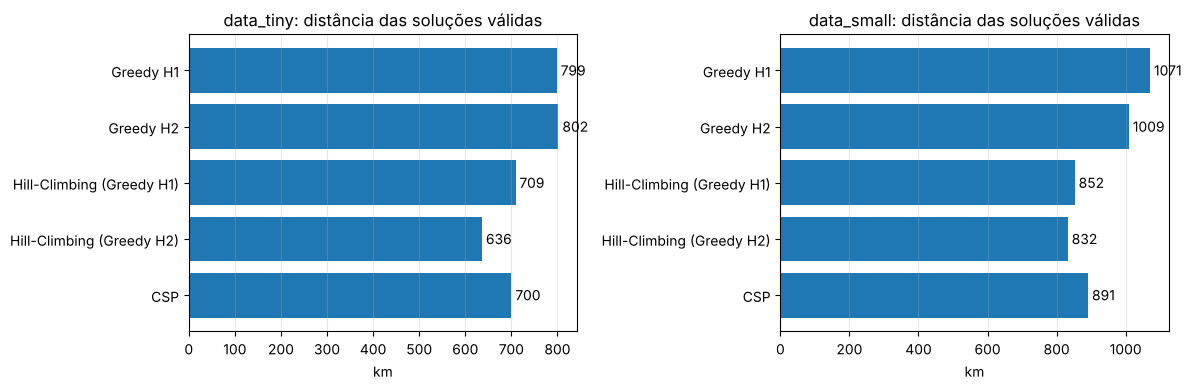

In [4]:
validos = resultados[resultados["Solução válida"]]
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
for eixo, nome in zip(eixos, problemas):
    dados = validos[validos["Dataset"] == nome]
    eixo.barh(dados["Algoritmo"], dados["Distância (km)"])
    for y, km in enumerate(dados["Distância (km)"]):
        eixo.text(km, y, f" {km:.0f}", va="center")
    eixo.set_title(f"{nome}: distância das soluções válidas")
    eixo.set_xlabel("km")
    eixo.invert_yaxis()
    eixo.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Melhores soluções

Rotas da solução com menos km em cada dataset.

In [5]:
for nome in problemas:
    melhor = validos[validos["Dataset"] == nome].sort_values("Distância (km)").iloc[0]
    print("=" * 90)
    print(f"{nome} — {melhor['Algoritmo']}\n")
    print_solution(problemas[nome], solucoes[(nome, melhor["Algoritmo"])])
    print()

data_tiny — Hill-Climbing (Greedy H2)

Solução válida | total: 636.31 km

Veículo 1 (capacidade 150 kg)
  30/10 09:00  pickup   Campos Leite                 [12, 23, 27, 28, 30, 33, 36, 38, 39] +37.7 km
  30/10 09:41  pickup   Hortas Valente               [5, 13, 25, 31, 32, 34, 37, 40] +23.6 km
  30/10 10:32  unload   Centro de Recolha 1          [5, 12, 13, 23, 25, 27, 28, 30, 31, 32, 33, 34, 36, 37, 38, 39, 40] +30.6 km
  30/10 10:47  load     Centro de Recolha 1          [36, 37, 38, 39, 40, 25, 26, 27, 28, 29, 30, 31, 5, 6] +0.0 km
  30/10 12:15  deliver  Casa 2                       [36, 37, 38, 39, 40]     +36.1 km
  30/10 13:13  deliver  Casa 4                       [30, 31]                 +36.3 km
  31/10 08:15  pickup   Campos Leite                 [1, 7, 15, 16, 18]       +54.9 km
  31/10 09:00  pickup   Hortas Valente               [2, 10, 19, 20, 21]      +23.6 km
  31/10 09:29  deliver  Loja 5                       [25, 26, 27, 28, 29]     +14.9 km
  31/10 10:13  deliver

### Comparação

- **Greedy:** encontra sempre uma solução válida, em poucos segundos. Não garante a melhor; a H2 orienta melhor a pesquisa no small (menos km).
- **A\*:** não encontra solução dentro do limite. O estado tem horas e cada estado gera dezenas de sucessores; como o A\* expande sempre o menor `g + h`, volta sempre aos estados do início e espalha-se em largura (ver `informed_search.ipynb`, secção 8). Está correto, mas não é viável neste problema.
- **Hill-Climbing:** dá as **melhores soluções** nos dois datasets, melhorando bastante o Greedy. O resultado depende da solução de partida, porque pára no primeiro ótimo local.
- **CSP:** encontra uma solução válida a partir do zero, sem precisar do Greedy, e com menos km do que o Greedy graças à restrição soft. Fica atrás do Hill-Climbing.

## 6. Conclusão

Modelámos o problema de recolha e distribuição com um verificador único (`model.py`) e aplicámos quatro técnicas de IA aos datasets `tiny` e `small`.

- O **Greedy** é a forma mais rápida de obter uma solução válida.
- O **Hill-Climbing**, a partir do Greedy, deu as melhores soluções.
- O **CSP** resolve o problema sem solução inicial e com todas as restrições, com um resultado intermédio.
- O **A\***, apesar de correto, não chega ao fim: garantir o ótimo neste problema exige explorar demasiados estados.

As janelas de tempo curtas e o limite de 24 h no armazém são as restrições que mais condicionam o problema: obrigam a várias viagens em horas específicas e tornam o espaço de estados muito grande.